# Evaluation

## Evaluate on different situation

### Load dataset and model

In [ ]:
import argparse
import os.path

import torch
from torch import nn, optim
from torch import nn
from torch.utils.data import DataLoader
from tqdm import tqdm
from dataset.dataset_loader import VideoDataset
import torch.nn.functional as F
from eval_3c.utils import manhattan_dist, t3c, is_human
import random

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(DEVICE)
# The parser setting
parser = argparse.ArgumentParser()
parser = VideoDataset.add_model_specific_args(parser)
parser.add_argument('--data_path', type=str, default='dataset/ATR_1F_3F_2024-12-25')
# parser.add_argument('--data_path', type=str, default='dataset/mul_fps_data')

parser.add_argument('--sequence_length', type=int, default=40)
parser.add_argument('--resolution', type=int, default=64)
parser.add_argument('--batch_size', type=int, default=16)
parser.add_argument('--num_workers', type=int, default=8)
parser.add_argument('--LR_RATE', type=int, default=1e-4)
parser.add_argument('--NUM_EPOCHS', type=int, default=100)
parser.add_argument('--iteration_num', type=int, default=1000)
args = parser.parse_args(args=[])
mulgpu = True
rgb = False

# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(args.data_path, args.sequence_length,rgb=rgb, train=True, resolution=args.resolution)

# dataloader for the trainning
dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=True
)

# dataloader for the evaluation
dataset = Dataset(args.data_path, args.sequence_length, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

from utils import fw_diffusion_vid, fw_diffusion_mot, MixedSequenceMaskGenerator
input_mot_channel = args.sequence_length * 2
mask_generator = MixedSequenceMaskGenerator(t2=args.sequence_length)

# The parameters for forward diffusion process
beta = torch.linspace(1e-4, 0.02, args.iteration_num) 
alpha = 1.0-beta
alpha_cum = torch.tensor([alpha[0]] + [torch.prod(alpha[:i+1]) for i in range(1, len(beta))])


from TimeSformer.VDT_cat_vm import VDT_cat

nhead = 6
depth = 12
patch_size= 2
hidden_size = 768
epoch = 100
in_channels = 6
input_size = 8

eps_est_model = VDT_cat(
    input_size=input_size,
    patch_size=patch_size,
    in_channels=in_channels,
    hidden_size=hidden_size,
    depth=depth,
    num_frames=args.sequence_length,
    num_heads=nhead,
    mlp_ratio=4.0,
    learn_sigma=False
    ).to(DEVICE)


from diffusers.models import AutoencoderKL
vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse").to(DEVICE)
vae.encoder.conv_in = nn.Conv2d(9, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, 9, kernel_size=3, stride=1, padding=1)


if mulgpu:
    input_dim = 3
    modelData = 'checkpoints_vae_3c_seg/vae_20250202_seg40.pth.tar'
    checkpoint = torch.load(modelData)
    state_dict = checkpoint['model_state_dict']
    state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
else:
    modelData = 'checkpoints_vae_seg/vae_40.pth.tar'
    checkpoint = torch.load(modelData)
    state_dict = checkpoint['model_state_dict']
        

vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse")
vae.encoder.conv_in = nn.Conv2d(input_dim, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, input_dim, kernel_size=3, stride=1, padding=1)
vae.load_state_dict(state_dict)
vae.to(DEVICE)

# freeze vae
for param in vae.parameters():
    param.requires_grad = False





### Evaluate one single real data's Manhattan distance with other data in the dataset

In [ ]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)
import random
from eval_3c.utils import manhattan_dist


dec_vid_list = []
rec_mot_list = []

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)
idx=13180
batch, vid_idx, path = valid_dataset[idx]
batch, mot = dict.values(batch)
mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)

vid = batch.to(DEVICE)
vid = vid.view(-1,64,64,9)
vid_obstacle = vid[:,:,:,0] + vid[:,:,:,1] + vid[:,:,:,3] + vid[:,:,:,4] + vid[:,:,:,5]
vid_human = vid[:,:,:,6]
vid_floor = vid[:,:,:,7]
vid = torch.cat((vid_obstacle.unsqueeze(3), vid_human.unsqueeze(3), vid_floor.unsqueeze(3)), dim=3)


dec_vid_list.append(vid)
rec_mot_list.append(mot[0].reshape(1,args.sequence_length,2))


# 随机抽取 n 个索引
random_indices = random.sample(range(len(valid_dataset)), 50)

# 从数据集中抽取数据
for idx in random_indices:
    batch, vid_idx, path = valid_dataset[idx]
    batch, mot = dict.values(batch)
    mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
    vid = batch.to(DEVICE)
    vid = vid.view(-1,64,64,9)
    vid_obstacle = vid[:,:,:,0] + vid[:,:,:,1] + vid[:,:,:,3] + vid[:,:,:,4] + vid[:,:,:,5]
    vid_human = vid[:,:,:,6]
    vid_floor = vid[:,:,:,7]
    vid = torch.cat((vid_obstacle.unsqueeze(3), vid_human.unsqueeze(3), vid_floor.unsqueeze(3)), dim=3)

    dec_vid_list.append(vid)
    rec_mot_list.append(mot[0].reshape(1,args.sequence_length,2))


frame_t = 10 
manhattan_distance = manhattan_dist(args, dec_vid_list, rec_mot_list, frame_t, input_dim)
torch.save(manhattan_distance, 'eval_3c/manhattan_distances_1.pt')


metadata exists in: dataset/ATR_1F_3F_2024-12-25/train/metadata_40.pkl


Frame 1 Manhattan Distances: {'background': tensor(0.1331), 'Human': tensor(0.0455), 'Floor': tensor(0.1152)}
Frame 2 Manhattan Distances: {'background': tensor(0.1150), 'Human': tensor(0.0458), 'Floor': tensor(0.0743)}
Frame 3 Manhattan Distances: {'background': tensor(0.0911), 'Human': tensor(0.0461), 'Floor': tensor(0.0527)}
Frame 4 Manhattan Distances: {'background': tensor(0.1730), 'Human': tensor(0.0447), 'Floor': tensor(0.1401)}
Frame 5 Manhattan Distances: {'background': tensor(0.0944), 'Human': tensor(0.0462), 'Floor': tensor(0.0535)}
Frame 6 Manhattan Distances: {'background': tensor(0.1898), 'Human': tensor(0.0539), 'Floor': tensor(0.1454)}
Frame 7 Manhattan Distances: {'background': tensor(0.1455), 'Human': tensor(0.0459), 'Floor': tensor(0.1107)}
Frame 8 Manhattan Distances: {'background': tensor(0.1317), 'Human': tensor(0.0461), 'Floor': tensor(0.1272)}
Frame 9 Manhattan Distances: {'background': tensor(0.1219), 'Human': tensor(0.0463), 'Floor': tensor(0.0781)}
Frame 10 M

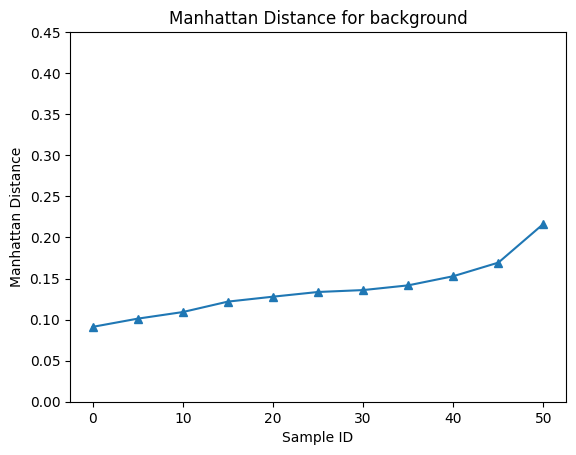

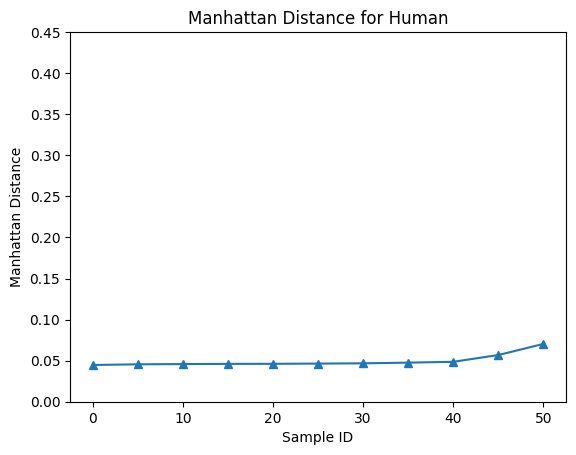

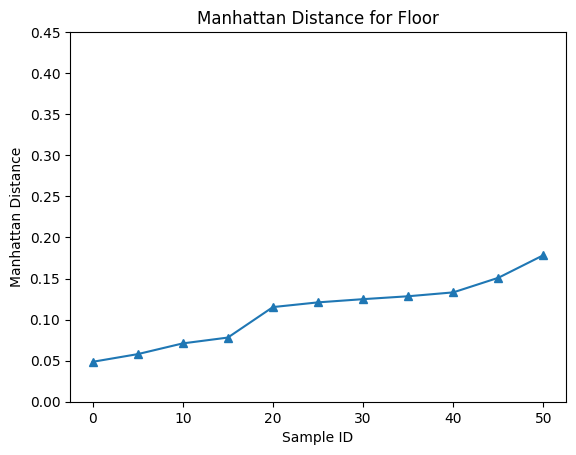

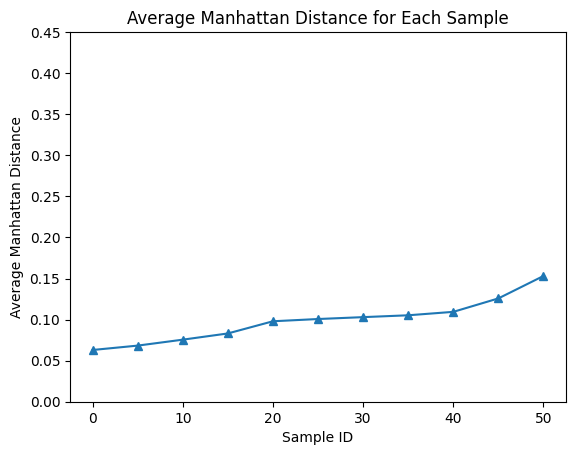

In [ ]:
from eval_3c.utils import visual_MD

# 读取 .pt 文件
distances,_ = torch.load('eval_3c/manhattan_distances_1.pt')
# print(distances)
visual_MD(distances)

### Evaluate multiple real data's Manhattan distances and calculate the average

In [ ]:
# 保留 is_human 为 True 的样本
def get_human_samples(dataset, num_samples):
    human_index = []
    count = 0
    while len(human_index) < num_samples:
        random_indices = random.sample(range(len(dataset)), num_samples - len(human_index))
        for idx in random_indices:
            sample,_,_ = dataset[idx]
            batch, mot = dict.values(sample)
            vid = t3c(batch).unsqueeze(0).to(DEVICE)
            if is_human(vid):
                rep_vid = vid.clone()
                rep_vid[:,10:] = rep_vid[:,10]
                dist = abs(torch.mean(rep_vid - vid))
                # print(dist)
                if dist > 0.0015:
                    human_index.append(idx)
                    count +=1
                    print(count)
            
        # print(len(human_index))
    return human_index
valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)

human_index = get_human_samples(valid_dataset, 350)
torch.save(human_index, 'eval_3c/human_late_index_350.pt')


metadata exists in: dataset/ATR_1F_3F_2024-12-25/train/metadata_40.pkl
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
2

In [ ]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)
from eval_3c.utils import manhattan_dist, t3c, is_human

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)

all_manhattan_distance = []
sample_count = 0
human_index = torch.load('eval_3c/human_late_index_350.pt')

print(len(human_index))
# 从数据集中抽取数据
for real_idx in human_index:
    dec_vid_list = []
    rec_mot_list = []

    batch, vid_idx, path = valid_dataset[real_idx]
    batch, mot = dict.values(batch)
    mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
    
    vid = t3c(batch).to(DEVICE)

    dec_vid_list.append(vid)
    rec_mot_list.append(mot[0].reshape(1,args.sequence_length,2))


    # 随机抽取 n 个索引
    random_indices = random.sample(range(len(valid_dataset)), 50)

    # 从数据集中抽取数据
    for idx in random_indices:
        batch, vid_idx, path = valid_dataset[idx]
        batch, mot = dict.values(batch)
        mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
        vid = t3c(batch).to(DEVICE)

        dec_vid_list.append(vid)
        rec_mot_list.append(mot[0].reshape(1,args.sequence_length,2))

    frame_t = 10 
    manhattan_distance, _ = manhattan_dist(args, dec_vid_list, rec_mot_list, frame_t, input_dim, pooled=True,time_evolution=True)
    all_manhattan_distance.append(manhattan_distance)
    sample_count += 1


# 将字典写入文件
torch.save(all_manhattan_distance, 'eval_3c/time_evolution/test_11_all_manhattan_distances.pt')



metadata exists in: dataset/ATR_1F_3F_2024-12-25/train/metadata_40.pkl
350
Frame 1 Manhattan Distances: {'background_early': tensor(0.0943), 'background_mid': tensor(0.0845), 'background_late': tensor(0.0762), 'Human_early': tensor(0.0719), 'Human_mid': tensor(0.0656), 'Human_late': tensor(0.0781), 'Floor_early': tensor(0.0701), 'Floor_mid': tensor(0.0574), 'Floor_late': tensor(0.0473)}
Frame 2 Manhattan Distances: {'background_early': tensor(0.1023), 'background_mid': tensor(0.1222), 'background_late': tensor(0.1188), 'Human_early': tensor(0.0484), 'Human_mid': tensor(0.0906), 'Human_late': tensor(0.0906), 'Floor_early': tensor(0.0867), 'Floor_mid': tensor(0.0976), 'Floor_late': tensor(0.0893)}
Frame 3 Manhattan Distances: {'background_early': tensor(0.0941), 'background_mid': tensor(0.0886), 'background_late': tensor(0.0912), 'Human_early': tensor(0.0453), 'Human_mid': tensor(0.0594), 'Human_late': tensor(0.0609), 'Floor_early': tensor(0.0750), 'Floor_mid': tensor(0.0639), 'Floor_lat

In [ ]:
import torch

# 读取 .pt 文件
all_distances = torch.load('eval_3c/time_evolution/test_11_all_manhattan_distances.pt')
# print((all_distances))
# 初始化字典以存储排序后的结果
all_sorted_distances = []
# channels = ['background', 'Human', 'Floor']
channels = ['background_early', 'background_mid', 'background_late', 'Human_early', 'Human_mid', 'Human_late', 'Floor_early', 'Floor_mid', 'Floor_late']

# print((all_distances))
for distances in all_distances:

    channel_distances = {channel: [] for channel in channels}
    sorted_sample_distances = {}
    for sample, distance in distances.items():
        for channel in channels:
            channel_distances[channel].append(distance[channel].item())
    
    for channel in channels:
        channel_distances[channel] = sorted(channel_distances[channel])

    all_sorted_distances.append(channel_distances)

# # 将结果存储为字典
# torch.save(all_sorted_distances, 'eval_3c/sorted_manhattan_distances_real_data.pt')

# 初始化字典以存储每个样本的平均曼哈顿距离
average_distances = {f'Sample {i+1}': {channel: 0 for channel in channels} for i in range(50)}
# print(average_distances)
# all_distances = torch.load('eval_3c/sorted_manhattan_distances_real_data.pt')

# 遍历所有曼哈顿距离，计算每个样本的总和
for distances in all_sorted_distances:
    for channel, distance in distances.items():
        for t, dist in enumerate(distance):
            # print(average_distances['Sample ' + str(t+1)][channel])
            average_distances['Sample ' + str(t+1)][channel] += dist

# 计算每个样本的平均曼哈顿距离
for t, distance in average_distances.items():
    average_distances[t] = {channel: torch.tensor(dist / len(all_sorted_distances)) for channel, dist in distance.items()}

# 打印每个样本的平均曼哈顿距离
print("Average Manhattan Distances for Each Sample:")
for sample, means in average_distances.items():
    print(f"{sample}: {means}")

# 将结果存储为字典
torch.save(average_distances, 'eval_3c/time_evolution/test_11_average_manhattan_distances_real_data.pt')

Average Manhattan Distances for Each Sample:
Sample 1: {'background_early': tensor(0.0899), 'background_mid': tensor(0.0911), 'background_late': tensor(0.0921), 'Human_early': tensor(0.0501), 'Human_mid': tensor(0.0594), 'Human_late': tensor(0.0621), 'Floor_early': tensor(0.0587), 'Floor_mid': tensor(0.0585), 'Floor_late': tensor(0.0581)}
Sample 2: {'background_early': tensor(0.0982), 'background_mid': tensor(0.0996), 'background_late': tensor(0.1008), 'Human_early': tensor(0.0585), 'Human_mid': tensor(0.0689), 'Human_late': tensor(0.0705), 'Floor_early': tensor(0.0671), 'Floor_mid': tensor(0.0669), 'Floor_late': tensor(0.0664)}
Sample 3: {'background_early': tensor(0.1024), 'background_mid': tensor(0.1038), 'background_late': tensor(0.1059), 'Human_early': tensor(0.0618), 'Human_mid': tensor(0.0717), 'Human_late': tensor(0.0735), 'Floor_early': tensor(0.0714), 'Floor_mid': tensor(0.0713), 'Floor_late': tensor(0.0715)}
Sample 4: {'background_early': tensor(0.1058), 'background_mid': te

In [ ]:
from eval_3c.utils import visual_MD

# 读取 .pt 文件
distances = torch.load('eval_3c/time_evolution/test_average_manhattan_distances_real_data.pt')
visual_MD(distances,time_evolution=True)

### Evaluate real data v.s. generated samples

In [ ]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)

from DDIM.ddim import ddim_generator
from utils import mask_vid_mot, visual_vid_mmot, gray3c_2color
import time
from eval_3c.utils import manhattan_dist, t3c
import random

all_manhattan_distance = []

# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241031_halfmask_rgb_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
modelData = 'checkpoints_mmVDT_vae_3c_seg/VDT_20250203_ATR_1F_3F_seg_3c_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241220_test_halfmask_seg_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'

ddim_generator = ddim_generator(nit=args.iteration_num,patch_size=patch_size,nhead=nhead,input_size=input_size, in_channels=in_channels, 
                                depth=depth, hidden_size=hidden_size, model_path=modelData, sequence_length=args.sequence_length,_cuda=0, cat=True)

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)

# 从数据集中抽取数据
human_index = torch.load('eval_3c/human_late_index_350.pt')
count = 0
for real_idx in human_index:
    vis_id = 0 # the index for visualization, default = 0
    pred_num = 50 # The number of multiple predictions
    frame_t = 10 
    count +=1
    test = True
    batch, vid_idx, path = valid_dataset[real_idx]
    print(vid_idx, path, count)
    batch, mot = dict.values(batch)

    mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
    start_time = time.time()

    vid = t3c(batch).permute(0,3,1,2).to(DEVICE)
    enc_vid = vae.encode(vid).latent_dist.sample()
    enc_vid = enc_vid.reshape(1, args.sequence_length,4,8,8).permute(0,1,3,4,2)

    a = enc_vid.to(DEVICE)
    b = mot.to(DEVICE)
    rec_vid_list = []
    rec_mot_list = []
    dec_vid_list = []

    ################ Original image #############################
    batch = batch.permute(0,3,1,2)
    dec_vid_list.append(vid.permute(0,2,3,1))
    rec_mot_list.append(b[vis_id].reshape(1,args.sequence_length,2))

    if rgb:
        batch_rgb = batch
    else:
        batch_rgb = gray3c_2color(batch)
        batch_rgb = torch.clamp(batch_rgb, 0,1)

    rec_vid_list.append(batch_rgb.permute(0,2,3,1))  
    # visual_vid_mmot(batch_rgb.permute(0,2,3,1), b[vis_id].reshape(1,args.sequence_length,2), rgb=True, frame_t=frame_t,grid=False)

    if test:
        diff_a = torch.randn([pred_num,args.sequence_length,input_size,input_size,in_channels-2]).to(DEVICE)
        diff_b = torch.randn([pred_num,args.sequence_length,2]).to(DEVICE)

    # Choose a mask type from 0 to 2
    # 0: prediction 1: backward 2: interpolation, t means the current frame
    mask_vid, mask_motion, _ = mask_generator(diff_a,diff_b, idx=0, t=frame_t)

    a = a.repeat(pred_num,1,1,1,1)
    b = b.repeat(pred_num,1,1)
    diff_a, diff_b = mask_vid_mot(mask_vid,mask_motion, a, b, diff_a, diff_b)

    with torch.no_grad():
        rec_vid, rec_mot = ddim_generator(diff_a,diff_b,mask_vid,mask_motion,ncal=16) #ncal: the ddim sample steps
     
    rec_vid = rec_vid.reshape(pred_num,args.sequence_length,input_size,input_size,in_channels-2).permute(0,1,4,2,3)

    ################ Decode image #############################
    for i in range(pred_num):  
        rec_mot_list.append(rec_mot[i]) 
        # print(rec_vid[i].permute(0,2,3,1)[0,5,0])
        dec_vid = vae.decode(rec_vid[i]).sample
        dec_vid_list.append(dec_vid.permute(0,2,3,1))
        # print(dec_vid_list[i].shape)
        if rgb:
            dec_rgb = torch.clamp(dec_vid, 0,1).permute(0,2,3,1)
        else:
            dec_rgb = gray3c_2color(dec_vid)
            dec_rgb = torch.clamp(dec_rgb, 0,1).permute(0,2,3,1)
        rec_vid_list.append(dec_rgb)
    
    manhattan_distance, _ = manhattan_dist(args, dec_vid_list, rec_mot_list, frame_t, input_dim, vis_list = [False, False, False], pooled=True, time_evolution=True)    
    all_manhattan_distance.append(manhattan_distance)

# 将字典写入文件
torch.save(all_manhattan_distance, 'eval_3c/time_evolution/test_11_all_generated_manhattan_distances_500x50.pt')




load model: success
metadata exists in: dataset/ATR_1F_3F_2024-12-25/train/metadata_40.pkl
719 dataset/ATR_1F_3F_2024-12-25/train/data_2024-10-24-16_54_21_3m_in_233_sec/6.mp4 1
Frame 1 Manhattan Distances: {'background_early': tensor(0.0562), 'background_mid': tensor(0.0730), 'background_late': tensor(0.0667), 'Human_early': tensor(0.0281), 'Human_mid': tensor(0.0562), 'Human_late': tensor(0.0531), 'Floor_early': tensor(0.0379), 'Floor_mid': tensor(0.0546), 'Floor_late': tensor(0.0473)}
Frame 2 Manhattan Distances: {'background_early': tensor(0.0611), 'background_mid': tensor(0.1155), 'background_late': tensor(0.1302), 'Human_early': tensor(0.0469), 'Human_mid': tensor(0.0672), 'Human_late': tensor(0.0984), 'Floor_early': tensor(0.0347), 'Floor_mid': tensor(0.0980), 'Floor_late': tensor(0.0969)}
Frame 3 Manhattan Distances: {'background_early': tensor(0.0558), 'background_mid': tensor(0.0796), 'background_late': tensor(0.0510), 'Human_early': tensor(0.0234), 'Human_mid': tensor(0.0437)

350
Average Manhattan Distances for Each Sample:
Sample 1: {'background_early': tensor(0.0564), 'background_mid': tensor(0.0674), 'background_late': tensor(0.0708), 'Human_early': tensor(0.0292), 'Human_mid': tensor(0.0463), 'Human_late': tensor(0.0475), 'Floor_early': tensor(0.0333), 'Floor_mid': tensor(0.0413), 'Floor_late': tensor(0.0433)}
Sample 2: {'background_early': tensor(0.0589), 'background_mid': tensor(0.0711), 'background_late': tensor(0.0751), 'Human_early': tensor(0.0318), 'Human_mid': tensor(0.0499), 'Human_late': tensor(0.0515), 'Floor_early': tensor(0.0356), 'Floor_mid': tensor(0.0444), 'Floor_late': tensor(0.0468)}
Sample 3: {'background_early': tensor(0.0606), 'background_mid': tensor(0.0739), 'background_late': tensor(0.0782), 'Human_early': tensor(0.0332), 'Human_mid': tensor(0.0518), 'Human_late': tensor(0.0537), 'Floor_early': tensor(0.0371), 'Floor_mid': tensor(0.0468), 'Floor_late': tensor(0.0494)}
Sample 4: {'background_early': tensor(0.0621), 'background_mid'

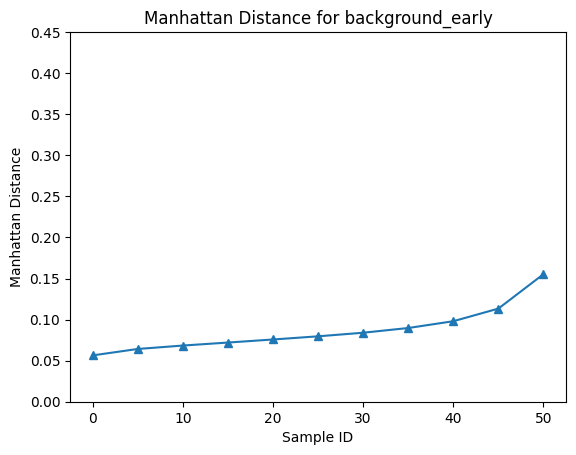

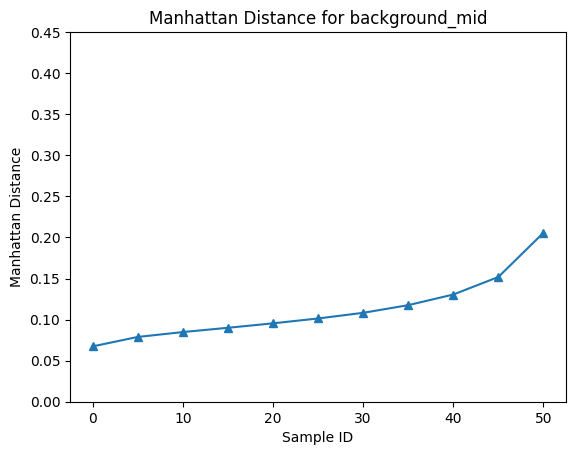

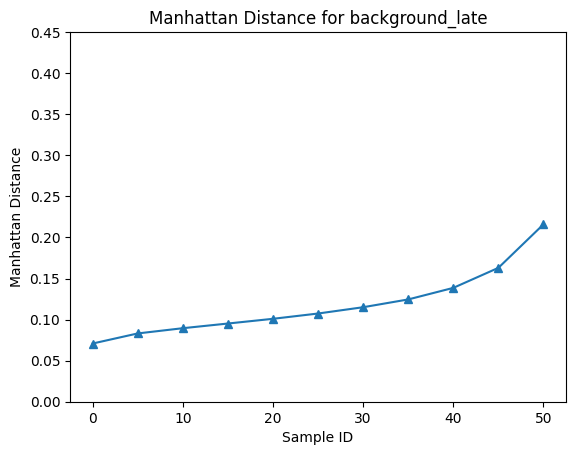

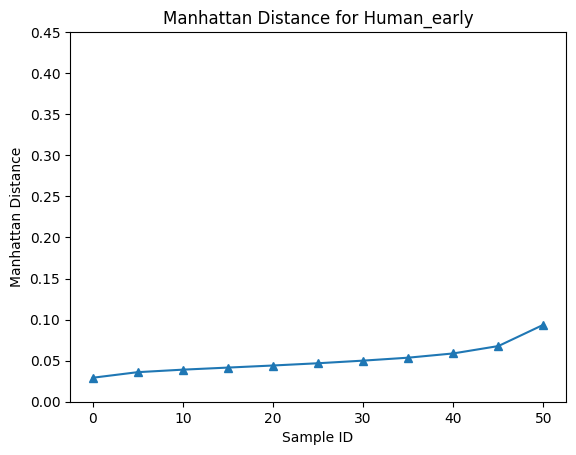

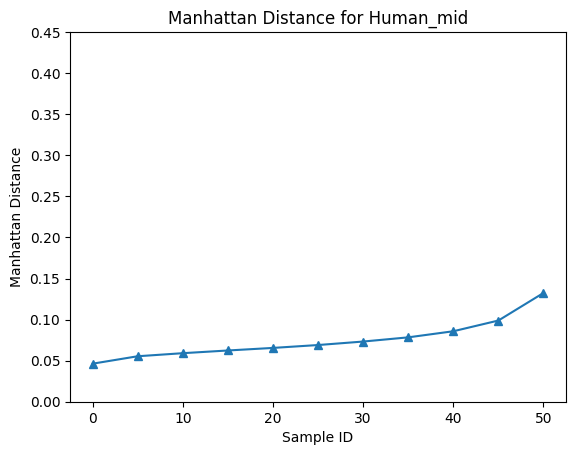

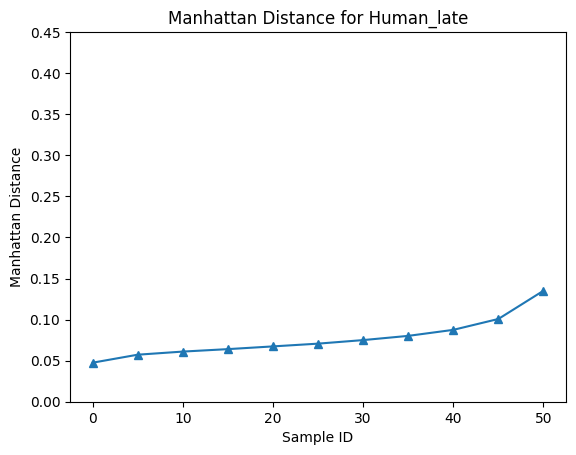

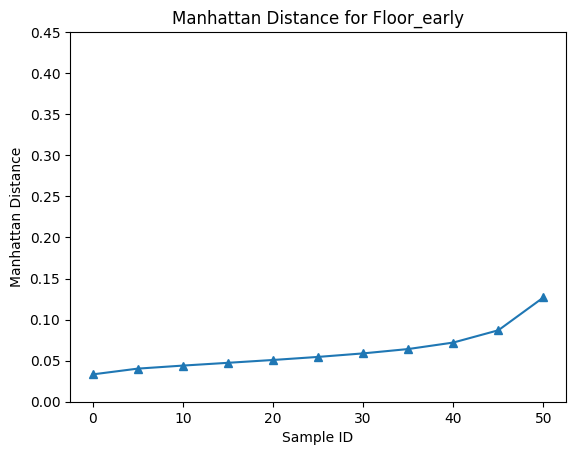

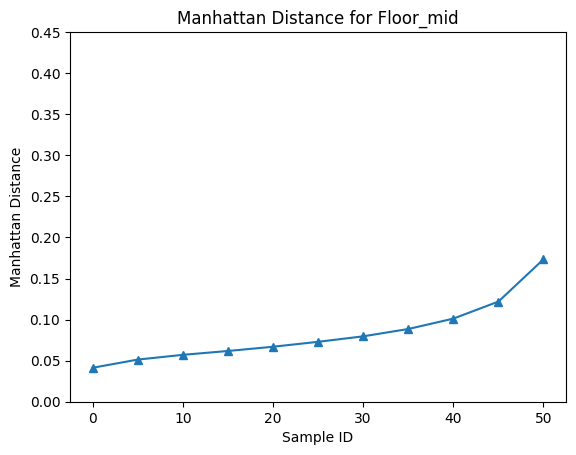

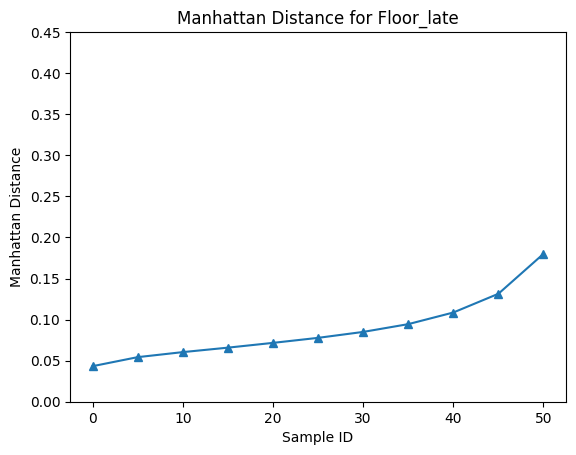

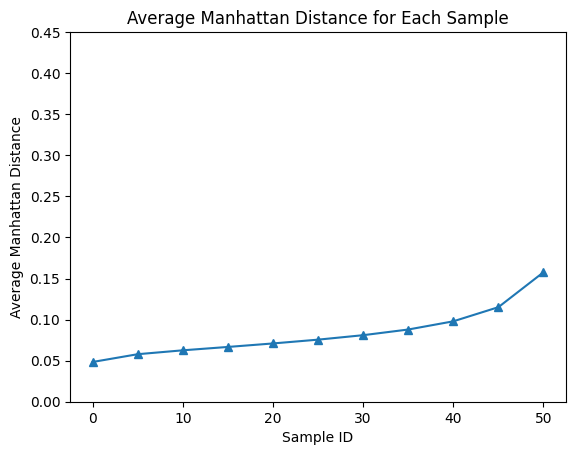

In [ ]:
import torch

# 读取 .pt 文件
all_distances = torch.load('eval_3c/time_evolution/test_11_all_generated_manhattan_distances_500x50.pt')

# 初始化字典以存储排序后的结果
all_sorted_distances = []
channels = ['background_early', 'background_mid', 'background_late', 'Human_early', 'Human_mid', 'Human_late', 'Floor_early', 'Floor_mid', 'Floor_late']

print(len(all_distances))
for distances in all_distances:

    channel_distances = {channel: [] for channel in channels}
    sorted_sample_distances = {}
    for sample, distance in distances.items():
        for channel in channels:
            channel_distances[channel].append(distance[channel].item())
    
    for channel in channels:
        channel_distances[channel] = sorted(channel_distances[channel])

    all_sorted_distances.append(channel_distances)

# # 将结果存储为字典
# torch.save(all_sorted_distances, 'eval/sorted_manhattan_distances_generated.pt')

# 初始化字典以存储每个样本的平均曼哈顿距离
average_distances = {f'Sample {i+1}': {channel: 0 for channel in channels} for i in range(50)}
# print(average_distances)
# sorted_distances = torch.load('eval/sorted_manhattan_distances_generated.pt')

# 遍历所有曼哈顿距离，计算每个样本的总和
for distances in all_sorted_distances:
    for channel, distance in distances.items():
        for t, dist in enumerate(distance):
            # print(average_distances['Sample ' + str(t+1)][channel])
            average_distances['Sample ' + str(t+1)][channel] += dist

# 计算每个样本的平均曼哈顿距离
for t, distance in average_distances.items():
    average_distances[t] = {channel: torch.tensor(dist / len(all_sorted_distances)) for channel, dist in distance.items()}

# 打印每个样本的平均曼哈顿距离
print("Average Manhattan Distances for Each Sample:")
for sample, means in average_distances.items():
    print(f"{sample}: {means}")

# 将结果存储为字典
torch.save(average_distances, 'eval_3c/time_evolution/test_11_average_manhattan_distances_generated.pt')

# Visualize the results
from eval_3c.utils import visual_MD

# 读取 .pt 文件
distances = torch.load('eval_3c/time_evolution/test_11_average_manhattan_distances_generated.pt')
visual_MD(distances, time_evolution=True)   

### Repeated last frame for baseline

In [ ]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)

from DDIM.ddim import ddim_generator
from utils import mask_vid_mot, visual_vid_mmot, gray3c_2color
import time
from eval_3c.utils import manhattan_dist, t3c
import random

all_manhattan_distance = []

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)

# 从数据集中抽取数据
human_index = torch.load('eval_3c/human_late_index_350.pt')
dec_vid_list = []
rec_mot_list = []
for real_idx in human_index:
    vis_id = 0 # the index for visualization, default = 0
    pred_num = 50 # The number of multiple predictions
    frame_t = 10 

    test = True
    batch, vid_idx, path = valid_dataset[real_idx]
    print(vid_idx, path)
    batch, mot = dict.values(batch)

    mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
    start_time = time.time()

    vid = t3c(batch).permute(0,3,1,2).to(DEVICE)
    dec_vid_list.append(vid.permute(0,2,3,1))

    repeat_lf_vid = vid.clone()
    repeat_lf_vid[10:] = vid[10].clone()
    repeat_lf_vid = repeat_lf_vid.repeat(pred_num,1,1,1,1)
    # print(repeat_lf_vid.shape)

    b = mot.to(DEVICE)
    repeat_mot = b[vis_id].clone()
    repeat_mot[10:] = repeat_mot[10:11].clone()
    repeat_mot = repeat_mot.repeat(pred_num,1,1)
    # print(repeat_mot.shape)
    rec_mot_list = []
    dec_vid_list = []

    ################ Original image #############################
    batch = batch.permute(0,3,1,2)
    dec_vid_list.append(vid.permute(0,2,3,1))
    rec_mot_list.append(b[vis_id].reshape(1,args.sequence_length,2))


    ################ Decode image #############################
    for i in range(pred_num):  
        rec_mot_list.append(repeat_mot[i].reshape(1,args.sequence_length,2)) 
        dec_vid_list.append(repeat_lf_vid[i].permute(0,2,3,1))
        # print(dec_vid_list[i].shape)
    
    manhattan_distance, _ = manhattan_dist(args, dec_vid_list, rec_mot_list, frame_t, input_dim, vis_list = [False, False, False], pooled=True, time_evolution=True)
    all_manhattan_distance.append(manhattan_distance)

# 将字典写入文件
torch.save(all_manhattan_distance, 'eval_3c/time_evolution/repeated_11_last_frame_manhattan_distances_500x50.pt')




metadata exists in: dataset/ATR_1F_3F_2024-12-25/train/metadata_40.pkl
719 dataset/ATR_1F_3F_2024-12-25/train/data_2024-10-24-16_54_21_3m_in_233_sec/6.mp4
Frame 1 Manhattan Distances: {'background_early': tensor(0.0527), 'background_mid': tensor(0.0657), 'background_late': tensor(0.0673), 'Human_early': tensor(0.0172), 'Human_mid': tensor(0.0328), 'Human_late': tensor(0.0328), 'Floor_early': tensor(0.0250), 'Floor_mid': tensor(0.0310), 'Floor_late': tensor(0.0333)}
Frame 2 Manhattan Distances: {'background_early': tensor(0.0527), 'background_mid': tensor(0.0657), 'background_late': tensor(0.0673), 'Human_early': tensor(0.0172), 'Human_mid': tensor(0.0328), 'Human_late': tensor(0.0328), 'Floor_early': tensor(0.0250), 'Floor_mid': tensor(0.0310), 'Floor_late': tensor(0.0333)}
Frame 3 Manhattan Distances: {'background_early': tensor(0.0527), 'background_mid': tensor(0.0657), 'background_late': tensor(0.0673), 'Human_early': tensor(0.0172), 'Human_mid': tensor(0.0328), 'Human_late': tensor

350
Average Manhattan Distances for Each Sample:
Sample 1: {'background_early': tensor(0.0671), 'background_mid': tensor(0.0962), 'background_late': tensor(0.1051), 'Human_early': tensor(0.0346), 'Human_mid': tensor(0.0694), 'Human_late': tensor(0.0717), 'Floor_early': tensor(0.0374), 'Floor_mid': tensor(0.0576), 'Floor_late': tensor(0.0641)}
Sample 2: {'background_early': tensor(0.0671), 'background_mid': tensor(0.0962), 'background_late': tensor(0.1051), 'Human_early': tensor(0.0346), 'Human_mid': tensor(0.0694), 'Human_late': tensor(0.0717), 'Floor_early': tensor(0.0374), 'Floor_mid': tensor(0.0576), 'Floor_late': tensor(0.0641)}
Sample 3: {'background_early': tensor(0.0671), 'background_mid': tensor(0.0962), 'background_late': tensor(0.1051), 'Human_early': tensor(0.0346), 'Human_mid': tensor(0.0694), 'Human_late': tensor(0.0717), 'Floor_early': tensor(0.0374), 'Floor_mid': tensor(0.0576), 'Floor_late': tensor(0.0641)}
Sample 4: {'background_early': tensor(0.0671), 'background_mid'

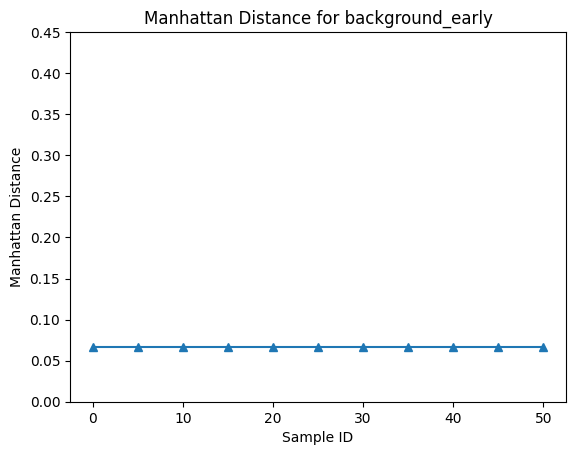

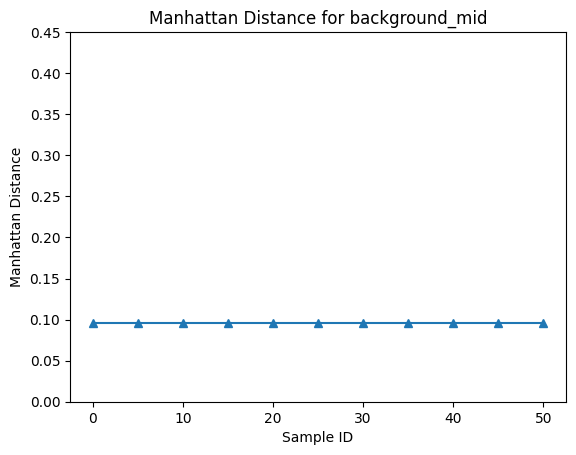

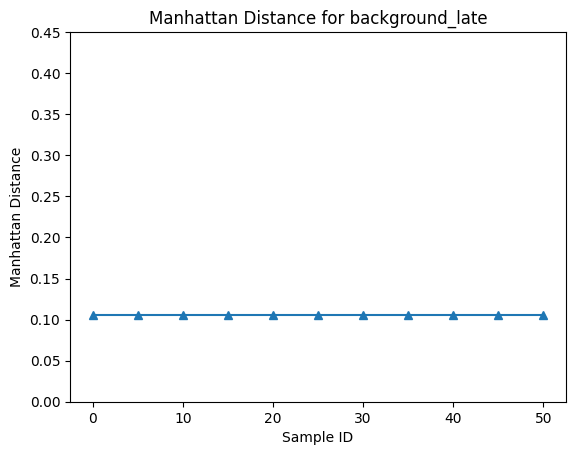

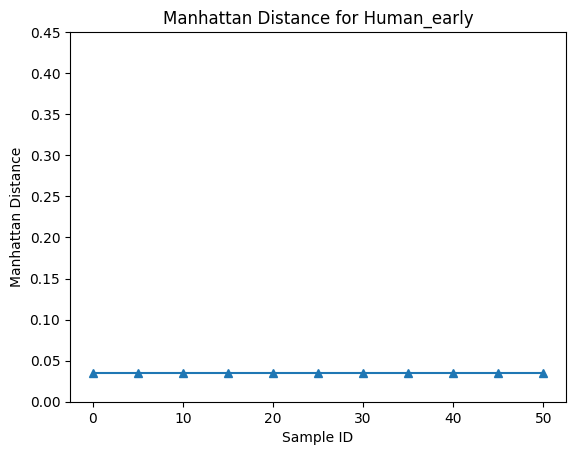

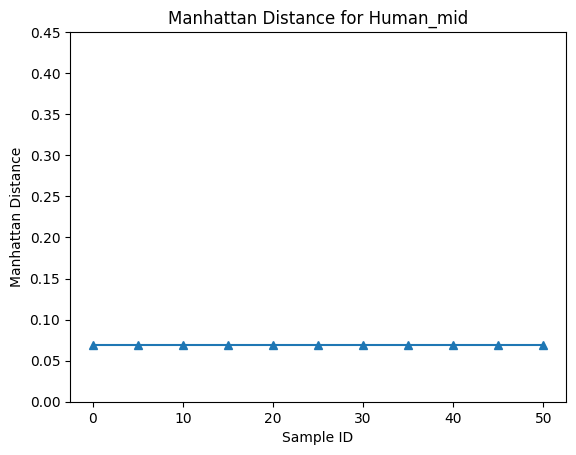

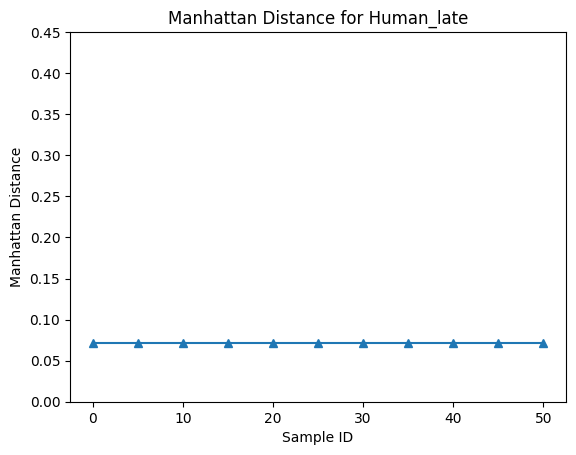

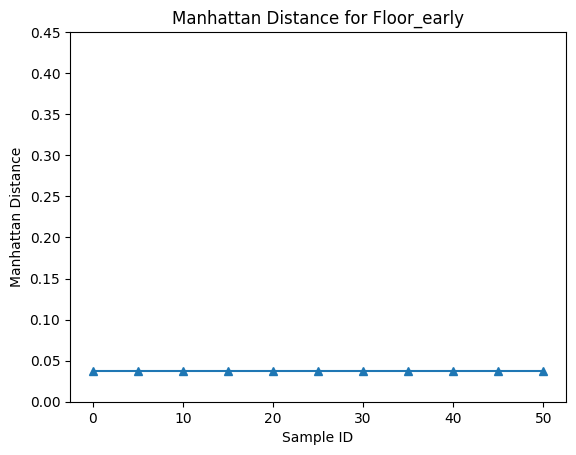

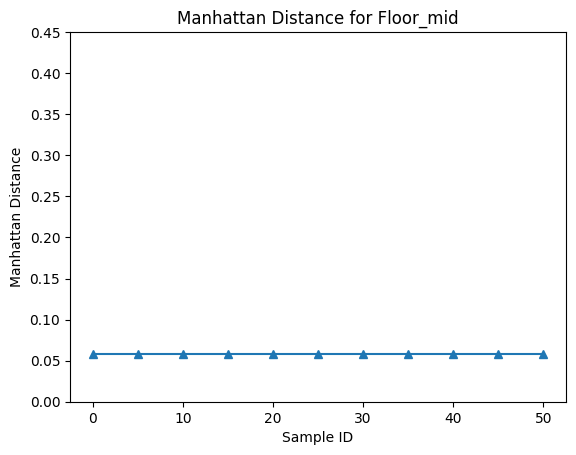

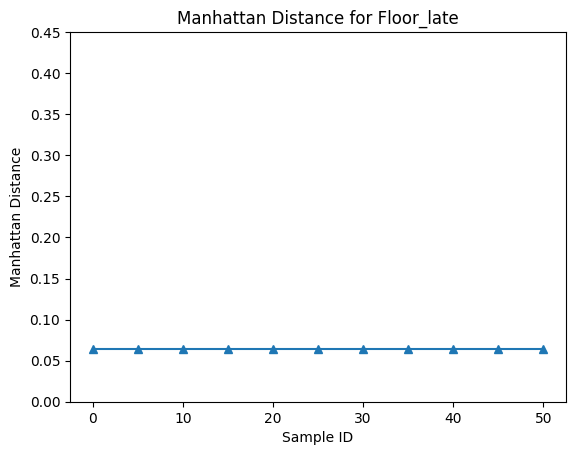

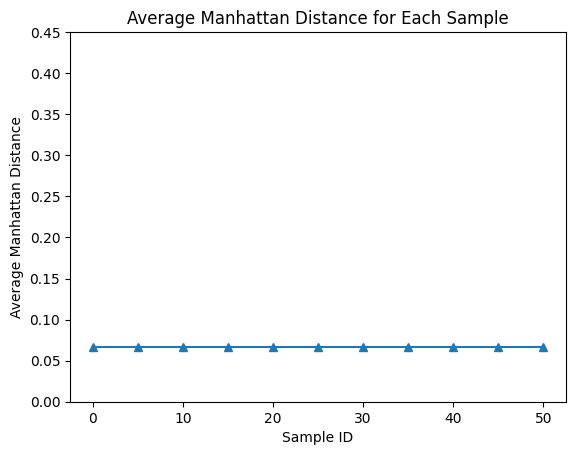

In [ ]:
import torch

# 读取 .pt 文件
all_distances = torch.load('eval_3c/time_evolution/repeated_11_last_frame_manhattan_distances_500x50.pt')

# 初始化字典以存储排序后的结果
all_sorted_distances = []
channels = ['background_early', 'background_mid', 'background_late', 'Human_early', 'Human_mid', 'Human_late', 'Floor_early', 'Floor_mid', 'Floor_late']

print(len(all_distances))
for distances in all_distances:

    channel_distances = {channel: [] for channel in channels}
    sorted_sample_distances = {}
    for sample, distance in distances.items():
        for channel in channels:
            channel_distances[channel].append(distance[channel].item())
    
    for channel in channels:
        channel_distances[channel] = sorted(channel_distances[channel])

    all_sorted_distances.append(channel_distances)

# # 将结果存储为字典
# torch.save(all_sorted_distances, 'eval/sorted_manhattan_distances_generated.pt')

# 初始化字典以存储每个样本的平均曼哈顿距离
average_distances = {f'Sample {i+1}': {channel: 0 for channel in channels} for i in range(50)}
# print(average_distances)
# sorted_distances = torch.load('eval/sorted_manhattan_distances_generated.pt')

# 遍历所有曼哈顿距离，计算每个样本的总和
for distances in all_sorted_distances:
    for channel, distance in distances.items():
        for t, dist in enumerate(distance):
            # print(average_distances['Sample ' + str(t+1)][channel])
            average_distances['Sample ' + str(t+1)][channel] += dist

# 计算每个样本的平均曼哈顿距离
for t, distance in average_distances.items():
    average_distances[t] = {channel: torch.tensor(dist / len(all_sorted_distances)) for channel, dist in distance.items()}

# 打印每个样本的平均曼哈顿距离
print("Average Manhattan Distances for Each Sample:")
for sample, means in average_distances.items():
    print(f"{sample}: {means}")

# 将结果存储为字典
torch.save(average_distances, 'eval_3c/time_evolution/repeated_11_last_frame_average_manhattan_distances_500x50.pt')

# Visualize the results
from eval_3c.utils import visual_MD

# 读取 .pt 文件
distances = torch.load('eval_3c/time_evolution/repeated_11_last_frame_average_manhattan_distances_500x50.pt')
visual_MD(distances, time_evolution=True)

## Summarize three figure in one

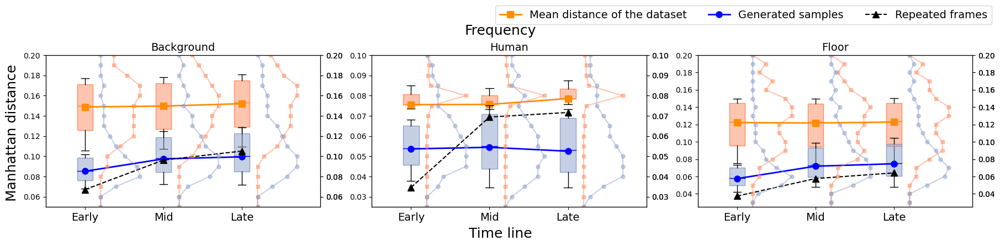

In [1]:
import torch
manhattan_distance_1 = torch.load('eval_3c/manhattan_distances_1.pt')
manhattan_distance_2 = torch.load('eval_3c/time_evolution/test_11_average_manhattan_distances_real_data.pt')
manhattan_distance_3 = torch.load('eval_3c/time_evolution/test_average_manhattan_distances_generated.pt')
repeat = torch.load('eval_3c/time_evolution/repeated_11_last_frame_average_manhattan_distances_500x50.pt')
# print(manhattan_distance_2)
from eval_3c.utils import visual_MD_combined, visual_MD_box
# visual_MD_combined(manhattan_distance_2, manhattan_distance_3,repeat=repeat, Freq=True, time_evolution=True, average=False)   
visual_MD_box(manhattan_distance_2, manhattan_distance_3,repeat=repeat, Freq=True, time_evolution=True, average=False)

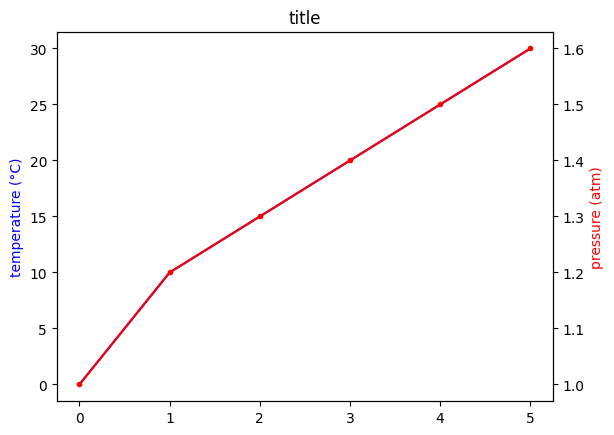

In [ ]:
import matplotlib.pyplot as plt

# 示例数据：时间 vs 摄氏温度
time = [0, 1, 2, 3, 4, 5]
temp_c = [0, 10, 15, 20, 25, 30]
fig, ax1 = plt.subplots()

# 左侧主轴画温度
ax1.plot(time, temp_c, 'b-')
ax1.set_ylabel('temperature (°C)', color='b')

# 右侧副轴画压力
ax2 = ax1.twinx()
pressure = [1, 1.2, 1.3, 1.4, 1.5, 1.6]
ax2.plot(time, pressure, 'r.-')
ax2.set_ylabel('pressure (atm)', color='r')

plt.title("title")
plt.show()

## Evaluate generated data on time axis

In [ ]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)

from DDIM.ddim import ddim_generator
from utils import mask_vid_mot, visual_vid_mmot, gray3c_2color
import time
from eval_3c.utils import manhattan_dist, t3c
import random

all_manhattan_distance = []
# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241031_halfmask_rgb_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
modelData = 'checkpoints_mmVDT_vae_3c_seg/VDT_20250203_ATR_1F_3F_seg_3c_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241220_test_halfmask_seg_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'

ddim_generator = ddim_generator(nit=args.iteration_num,patch_size=patch_size,nhead=nhead,input_size=input_size, in_channels=in_channels, 
                                depth=depth, hidden_size=hidden_size, model_path=modelData, sequence_length=args.sequence_length,_cuda=0, cat=True)

valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)

# 从数据集中抽取数据
real_data_random_indices = random.sample(range(len(valid_dataset)), 10)
for real_idx in real_data_random_indices:
    vis_id = 0 # the index for visualization, default = 0
    pred_num = 100 # The number of multiple predictions
    frame_t = 10 

    test = True
    batch, vid_idx, path = valid_dataset[real_idx]
    print(vid_idx, path)
    batch, mot = dict.values(batch)

    mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
    start_time = time.time()

    vid = t3c(batch).permute(0,3,1,2).to(DEVICE)
    enc_vid = vae.encode(vid).latent_dist.sample()
    enc_vid = enc_vid.reshape(1, args.sequence_length,4,8,8).permute(0,1,3,4,2)

    a = enc_vid.to(DEVICE)
    b = mot.to(DEVICE)
    rec_vid_list = []
    rec_mot_list = []
    dec_vid_list = []

    ################ Original image #############################
    batch = batch.permute(0,3,1,2)
    dec_vid_list.append(vid.permute(0,2,3,1))
    rec_mot_list.append(b[vis_id].reshape(1,args.sequence_length,2))
    if rgb:
        batch_rgb = batch
    else:
        batch_rgb = gray3c_2color(batch)
        batch_rgb = torch.clamp(batch_rgb, 0,1)

    # visual_vid_mmot(batch_rgb.permute(0,2,3,1), b[vis_id].reshape(1,args.sequence_length,2), rgb=True, frame_t=frame_t,grid=False)

    if test:
        diff_a = torch.randn([pred_num,args.sequence_length,input_size,input_size,in_channels-2]).to(DEVICE)
        diff_b = torch.randn([pred_num,args.sequence_length,2]).to(DEVICE)

    # Choose a mask type from 0 to 2
    # 0: prediction 1: backward 2: interpolation, t means the current frame
    mask_vid, mask_motion, _ = mask_generator(diff_a,diff_b, idx=0, t=frame_t)


    a = a.repeat(pred_num,1,1,1,1)
    b = b.repeat(pred_num,1,1)
    diff_a, diff_b = mask_vid_mot(mask_vid,mask_motion, a, b, diff_a, diff_b)

    with torch.no_grad():
        rec_vid, rec_mot = ddim_generator(diff_a,diff_b,mask_vid,mask_motion,ncal=16) #ncal: the ddim sample steps
        
    rec_vid = rec_vid.reshape(pred_num,args.sequence_length,input_size,input_size,in_channels-2).permute(0,1,4,2,3)

    ################ Decode image #############################
    for i in range(pred_num):  
        rec_mot_list.append(rec_mot[i]) 
        # print(rec_vid[i].permute(0,2,3,1)[0,5,0])
        dec_vid = vae.decode(rec_vid[i]).sample
        dec_vid_list.append(dec_vid.permute(0,2,3,1))
        if rgb:
            dec_rgb = torch.clamp(dec_vid, 0,1).permute(0,2,3,1)
        else:
            dec_rgb = gray3c_2color(dec_vid)
            dec_rgb = torch.clamp(dec_rgb, 0,1).permute(0,2,3,1)
        rec_vid_list.append(dec_rgb)
    manhattan_distance,_ = manhattan_dist(args, dec_vid_list, rec_mot_list, frame_t, input_dim, mean=False)
    all_manhattan_distance.append(manhattan_distance)

torch.save(all_manhattan_distance, 'eval_3c/all_generated_time_10x100_2.pt')


load model: success
metadata exists in: dataset/ATR_1F_3F_2024-12-25/train/metadata_40.pkl
128 dataset/ATR_1F_3F_2024-12-25/train/2024-07-16_14-51-32/20.mp4
Frame 1 Manhattan Distances: {'background': tensor([0.0474, 0.0808, 0.0701, 0.0725, 0.0693, 0.0925, 0.0789, 0.0928, 0.0911,
        0.0859, 0.1160, 0.0979, 0.1145, 0.1104, 0.1113, 0.1069, 0.1055, 0.0933,
        0.1304, 0.2534, 0.1936, 0.1975, 0.1626, 0.1616, 0.1494, 0.1702, 0.1228,
        0.1116, 0.1082, 0.1079]), 'Human': tensor([0.0059, 0.0093, 0.0049, 0.0049, 0.0066, 0.0066, 0.0073, 0.0066, 0.0105,
        0.0134, 0.0105, 0.0068, 0.0088, 0.0107, 0.0095, 0.0139, 0.0093, 0.0095,
        0.0085, 0.0093, 0.0073, 0.0100, 0.0076, 0.0056, 0.0088, 0.0051, 0.0063,
        0.0066, 0.0049, 0.0071]), 'Floor': tensor([0.0376, 0.0623, 0.0552, 0.0537, 0.0515, 0.0803, 0.0645, 0.0737, 0.0759,
        0.0688, 0.0969, 0.0891, 0.1045, 0.1084, 0.1038, 0.1125, 0.1006, 0.0815,
        0.1248, 0.2295, 0.1741, 0.1624, 0.1460, 0.1392, 0.1318, 0.1467, 0

In [ ]:
import torch

# 读取 .pt 文件
all_distances = torch.load('eval_3c/all_generated_time_10x100_2.pt')

# 初始化字典以存储排序后的结果
all_sorted_distances = []
channels = ['background', 'Human', 'Floor']

print(len(all_distances))
for distances in all_distances:

    channel_distances = {channel: [] for channel in channels}
    sorted_sample_distances = {}
    for sample, distance in distances.items():
        for channel in channels:
            # print(distance)
            channel_distances[channel].append(distance[channel])

    all_sorted_distances.append(channel_distances)
# print(all_sorted_distances)

# 初始化字典以存储每个样本的平均曼哈顿距离
average_distances = {f'Sample {i+1}': {channel: 0 for channel in channels} for i in range(100)}
# print(average_distances)

# 遍历所有曼哈顿距离，计算每个样本的总和
for distances in all_sorted_distances:
    for channel, distance in distances.items():
        for t, dist in enumerate(distance):
            # print(average_distances['Sample ' + str(t+1)][channel])
            average_distances['Sample ' + str(t+1)][channel] += dist

# 计算每个样本的平均曼哈顿距离
for t, distance in average_distances.items():
    average_distances[t] = {channel: torch.tensor(dist / len(all_sorted_distances)) for channel, dist in distance.items()}

# 打印每个样本的平均曼哈顿距离
print("Average Manhattan Distances for Each Sample:")
for sample, means in average_distances.items():
    print(f"{sample}: {means}")

# 将结果存储为字典
torch.save(average_distances, 'eval/average_manhattan_distances_time_generated.pt')



10
Average Manhattan Distances for Each Sample:
Sample 1: {'background': tensor([0.0355, 0.0449, 0.0491, 0.0521, 0.0499, 0.0582, 0.0613, 0.0771, 0.0598,
        0.0559, 0.0601, 0.0569, 0.0683, 0.0713, 0.0930, 0.0847, 0.1118, 0.0766,
        0.0903, 0.0924, 0.0952, 0.0731, 0.0739, 0.0754, 0.0704, 0.0758, 0.0953,
        0.0787, 0.0814, 0.0804]), 'Human': tensor([0.0092, 0.0106, 0.0096, 0.0095, 0.0109, 0.0107, 0.0128, 0.0135, 0.0105,
        0.0100, 0.0096, 0.0091, 0.0148, 0.0163, 0.0150, 0.0170, 0.0101, 0.0121,
        0.0118, 0.0103, 0.0123, 0.0108, 0.0097, 0.0104, 0.0096, 0.0104, 0.0103,
        0.0110, 0.0111, 0.0123]), 'Floor': tensor([0.0239, 0.0313, 0.0372, 0.0393, 0.0370, 0.0470, 0.0493, 0.0703, 0.0502,
        0.0483, 0.0494, 0.0461, 0.0526, 0.0567, 0.0775, 0.0733, 0.1008, 0.0695,
        0.0804, 0.0788, 0.0842, 0.0587, 0.0607, 0.0619, 0.0579, 0.0633, 0.0857,
        0.0677, 0.0708, 0.0686])}
Sample 2: {'background': tensor([0.0361, 0.0837, 0.0733, 0.0900, 0.0759, 0.1074, 0.0818

In [ ]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
import numpy as np

# 读取 .pt 文件
distances = torch.load('eval/average_manhattan_distances_time_generated.pt')


# 定义 channel 名称和颜色
# channels = ['undetected_obs', 'ceiling', 'wall', 'detected_furniture', 'door', 'Human', 'Floor']
channels = ['background', 'Human', 'Floor']

colors = sns.color_palette("Set2", n_colors=8)

# 提取每个 channel 的曼哈顿距离
channel_distances = {channel: [] for channel in channels}

for sample, distance in distances.items():
    for channel in channels:
        channel_distances[channel].append(distance[channel].tolist())


(30, 41)
(30, 27)
(30, 32)
background 41
(30, 51)
(30, 43)
(30, 6)
Human 51
(30, 40)
(30, 29)
(30, 31)
Floor 40


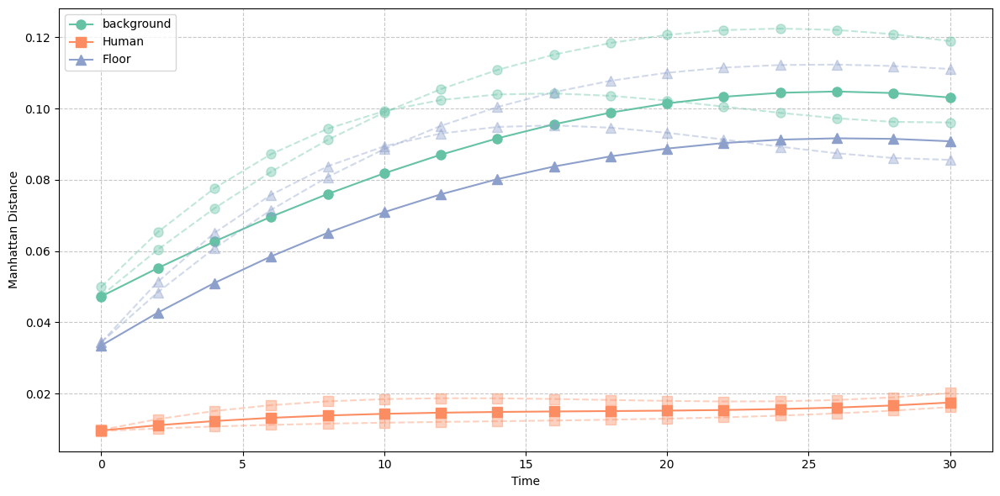

In [ ]:
# 设置时间间距
time_interval = 2

# 设置分组数量
n_clusters = 3

# 绘制拟合曲线
plt.figure(figsize=(12, 6))
marker = ['o', 's', '^', 'x', '*', '2', '<', '>',  '3', '4', 'v', 'D']

max_num = 0
for i, (channel, color) in enumerate(zip(channels, colors)):
    # 将每个样本的曼哈顿距离转换为 numpy 数组，并转置为 [t=30, sample个数] 的形式
    data = np.array(channel_distances[channel]).T

    # 使用 KMeans 将数据分成 n_clusters 组
    kmeans = KMeans(n_clusters=n_clusters, random_state=0).fit(data.T)
    labels = kmeans.labels_

    # 计算时间点
    time_points = np.arange(0, len(data))

    for cluster in range(n_clusters):
        group = data[:, labels == cluster]
        if group.shape[1] > max_num:
            max_num = group.shape[1]

    for cluster in range(n_clusters):
        # 分别提取每组数据
        group = data[:, labels == cluster]
        print(group.shape)
        # 拟合每组数据
        group_mean = np.mean(group, axis=1)
        poly = np.poly1d(np.polyfit(time_points, group_mean, 3))
        time_step = time_points[::time_interval]
        time_step = np.append(time_step, len(data))
        # print(time_step)

       # 绘制数据点和拟合曲线
        if group.shape[1] == max_num:  # 只为第一个 cluster 添加图例条目
            plt.plot(time_step, poly(time_step),marker[i]+'-', label=f'{channel}', color=color, markersize=8)
        else:
            plt.plot(time_step, poly(time_step), marker[i]+'--', color=color, alpha=0.4, markersize=8)
    print(channel, max_num)
    max_num = 0


plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlabel('Time')
plt.ylabel('Manhattan Distance')
# plt.title('Manhattan Distance Over Time for Each Channel')

plt.tight_layout()
plt.show()

(30, 100)
<module 'time' (built-in)>
(30, 85) (0.4, 0.7607843137254902, 0.6470588235294118)
(30, 15) (0.9882352941176471, 0.5529411764705883, 0.3843137254901961)
(30, 100)
<module 'time' (built-in)>
(30, 72) (0.4, 0.7607843137254902, 0.6470588235294118)
(30, 28) (0.9882352941176471, 0.5529411764705883, 0.3843137254901961)
(30, 100)
<module 'time' (built-in)>
(30, 72) (0.4, 0.7607843137254902, 0.6470588235294118)
(30, 28) (0.9882352941176471, 0.5529411764705883, 0.3843137254901961)
(30, 100)
<module 'time' (built-in)>
(30, 57) (0.4, 0.7607843137254902, 0.6470588235294118)
(30, 43) (0.9882352941176471, 0.5529411764705883, 0.3843137254901961)


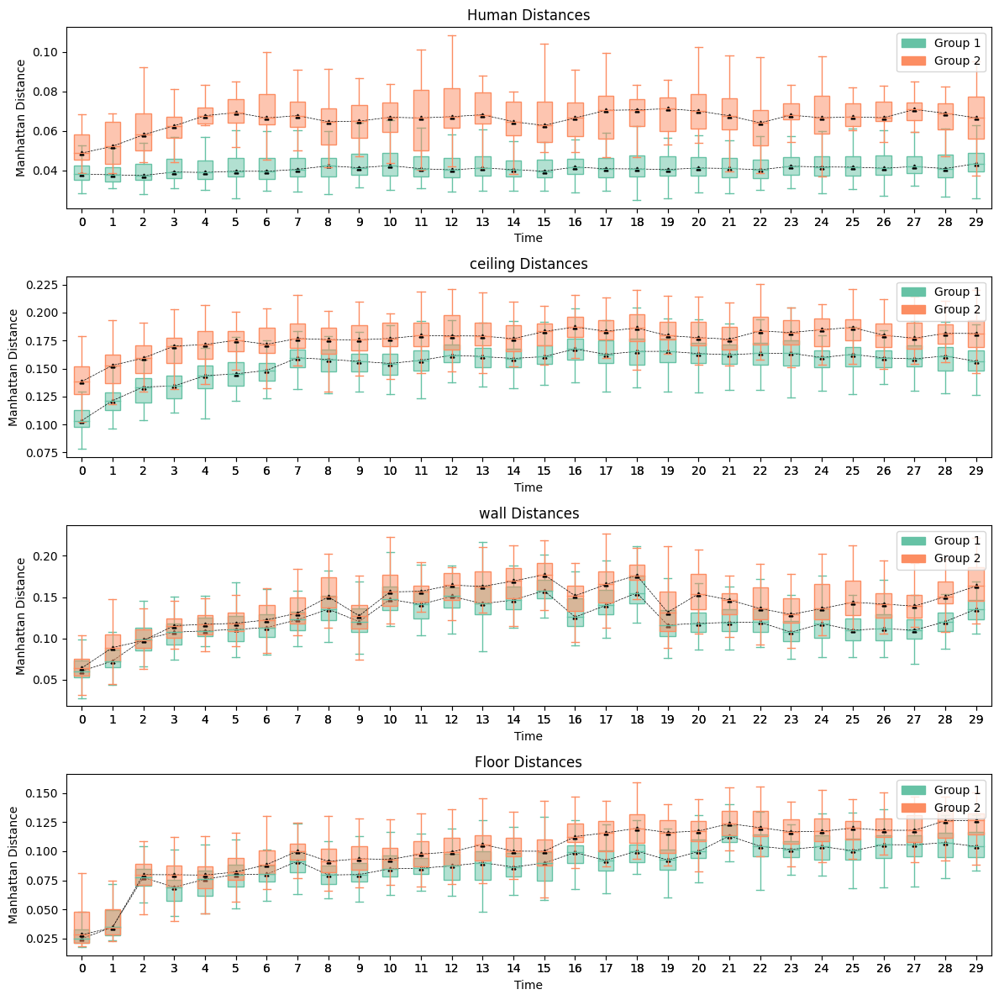

In [ ]:
import matplotlib.patches as mpatches
from sklearn.cluster import KMeans
import matplotlib.colors as mcolors

# 设置时间间距
time_interval = 1

# 设置分组数量
n_clusters = 2
# 绘制箱形图
plt.figure(figsize=(12, 12))

for i, (channel, color) in enumerate(zip(channels, colors)):
    # 将每个样本的曼哈顿距离转换为 numpy 数组，并转置为 [t=30, sample个数] 的形式
    data = np.array(channel_distances[channel]).T
    print(data.shape)
    # 使用 KMeans 将数据分成 n_clusters 组
    kmeans = KMeans(n_clusters=n_clusters, random_state=0).fit(data.T)
    labels = kmeans.labels_

    # 计算时间点
    time_points = np.arange(0, len(data) * time_interval, time_interval)
    print(time)
    plt.subplot(len(channels), 1, i + 1)
    for cluster in range(n_clusters):
        # 分别提取每组数据
        group = data[:, labels == cluster]
        color_idx = colors[cluster % len(colors)]
        if group.shape[1] > 50:
            color_idx = colors[0]
        else:
            color_idx = colors[1]

        # 设置透明度
        facecolor = mcolors.to_rgba(color_idx, alpha=0.5)
        edgecolor = mcolors.to_rgba(color_idx, alpha=1.0)
        # 绘制箱形图
        data_to_plot = [group[t] for t in range(len(group))]
        box = plt.boxplot(data_to_plot, positions=time_points, patch_artist=True,
                    boxprops=dict(facecolor=facecolor, color=edgecolor),
                    medianprops=dict(color=edgecolor),
                    whiskerprops=dict(color=edgecolor),
                    capprops=dict(color=edgecolor),
                    showfliers=False,
                    widths=0.5)
        print(group.shape,color_idx)
        # 提取中位数值并连线
        medians = [item.get_ydata()[0] for item in box['medians']]
        plt.plot(time_points, medians, color='black', linestyle='--', linewidth=0.5, marker='^',markersize=3.5)


    plt.xlabel('Time')
    plt.ylabel('Manhattan Distance')
    plt.title(f'{channel} Distances')
    # plt.xticks(np.arange(0, len(data), step=5))  # 设置横坐标为 0, 5, 10, 15, 20, 25, 30
    # 创建图例条目
    legend_patches = [mpatches.Patch(color=colors[cluster % len(colors)], label=f'Group {cluster + 1}') for cluster in range(n_clusters)]
    plt.legend(handles=legend_patches, loc='upper right')

    # y_tick = np.arange(0, 0.3, 0.05)
    # plt.yticks(y_tick)

plt.tight_layout()
plt.show()


In [ ]:
plt.figure(figsize=(12, 12))

#  计算所有 channel 的平均曼哈顿距离
average_distances = np.mean([np.array(channel_distances[channel]) for channel in channels], axis=0).T

# 使用 KMeans 将平均数据分成 n_clusters 组
kmeans = KMeans(n_clusters=n_clusters, random_state=0).fit(average_distances.T)
labels = kmeans.labels_

# 计算时间点
time_points = np.arange(0, len(average_distances) * time_interval, time_interval)

plt.subplot(len(channels) + 1, 1, 1)
for cluster in range(n_clusters):
    # 分别提取每组数据
    group = average_distances[:, labels == cluster]
    print(group.shape)
    # 设置透明度
    facecolor = mcolors.to_rgba(color_idx, alpha=0.5)
    edgecolor = mcolors.to_rgba(color_idx, alpha=1.0)
    # 绘制箱形图
    data_to_plot = [group[t] for t in range(len(group))]
    box = plt.boxplot(data_to_plot, positions=time_points, patch_artist=True,
                boxprops=dict(facecolor=facecolor, color=edgecolor),
                medianprops=dict(color=edgecolor),
                whiskerprops=dict(color=edgecolor),
                capprops=dict(color=edgecolor),
                showfliers=False,
                widths=0.5)
    print(group.shape,color_idx)
    # 提取中位数值并连线
    medians = [item.get_ydata()[0] for item in box['medians']]
    plt.plot(time_points, medians, color='black', linestyle='--', linewidth=0.5, marker='^',markersize=3.5)
    
plt.xlabel('Time')
plt.ylabel('Manhattan Distance')
plt.title('Average Distances')
plt.xticks(np.arange(0, len(average_distances), step=5))  # 设置横坐标为 0, 5, 10, 15, 20, 25, 30
# 创建图例条目
legend_patches = [mpatches.Patch(color=colors[cluster % len(colors)], label=f'Group {cluster + 1}') for cluster in range(n_clusters)]
plt.legend(handles=legend_patches, loc='upper right')

plt.tight_layout()
plt.show()
